In [2]:
import itertools
import random
import networkx as nx

import os
import glob
import time
import itertools
import random
import numpy as np
import networkx as nx
import pandas as pd
from PIL import Image
from pathlib import Path
from skimage.measure import regionprops
import matplotlib as mpl

# skimage.graph API 互換インポート
try:
    from skimage.graph import rag_boundary
except ImportError:
    from skimage.future.graph import rag_boundary



In [2]:
%cd /home/nodokaizm/code/mrcnn_multi_domain

/home/nodokaizm/code/mrcnn_multi_domain


# ここから

Counts per species:
 species
acapod     11
alllit     54
burspi    106
euclon     32
exostr     21
hakdac    106
dtype: int64
Saved table -> v_to_nearest_ray_distances.csv


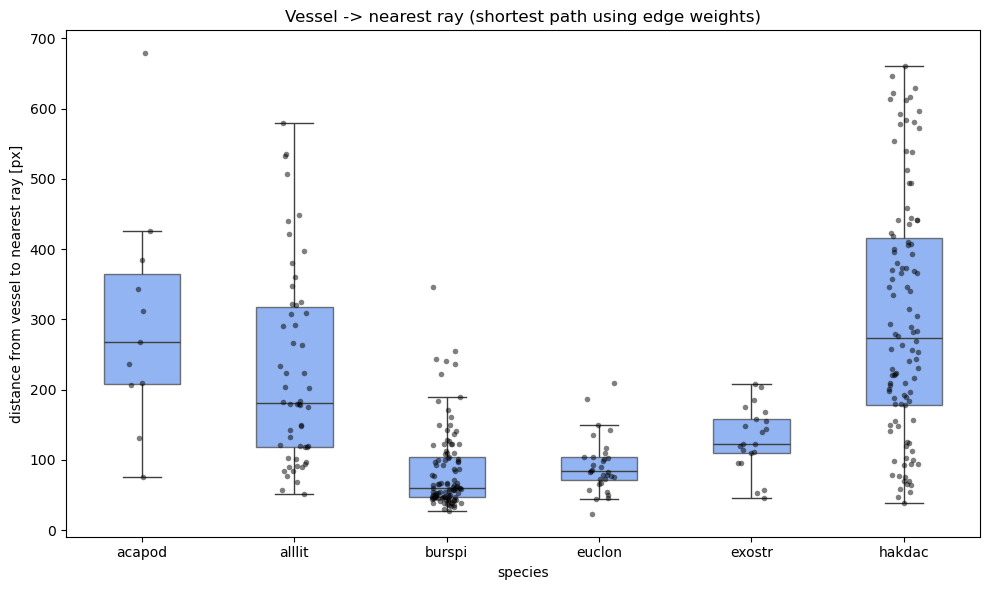

Saved plot -> v_to_nearest_ray_boxplot.png

Summary per species:
          count        mean         std        min         25%         50%  \
species                                                                     
acapod    11.0  297.509270  164.021467  76.363600  208.193531  267.441246   
alllit    54.0  226.917712  139.654082  52.214337  118.639600  181.269694   
burspi   106.0   84.320459   57.007745  27.870633   46.644066   60.584965   
euclon    32.0   92.086544   39.467655  23.491939   71.668528   83.914179   
exostr    21.0  130.241387   45.942290  45.135106  110.429850  123.267137   
hakdac   106.0  301.709056  172.220658  38.099507  177.974157  273.134508   

                75%         max  
species                          
acapod   364.065619  678.640290  
alllit   317.534340  578.955103  
burspi   104.268122  345.726812  
euclon   103.693700  209.176032  
exostr   157.836232  208.544962  
hakdac   416.295704  660.829125  


In [3]:
# -*- coding: utf-8 -*-
import os
import re
import glob
import pickle
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# ===== ユーザー設定 =====
graph_dir = 'graphs_vpr_without_clearborder'
out_csv   = 'v_to_nearest_ray_distances.csv'
out_png   = 'v_to_nearest_ray_boxplot.png'

# ピクセル→µm 変換したい場合は、ピクセルサイズ(µm/px)を指定（未使用なら None）
PIXEL_SIZE_UM = None  # 例: 0.5 にすると 0.5 µm/px で換算

# ===== ユーティリティ =====
def infer_species_from_filename(fname: str) -> str:
    """
    ファイル名の先頭の英字連続部分を species code として抽出。
    例: 'acapod2_01_rag.gpickle' -> 'acapod'
    """
    base = os.path.basename(fname)
    m = re.match(r'([A-Za-z]+)', base)
    return m.group(1).lower() if m else base

def infer_image_id_from_filename(fname: str) -> str:
    """
    拡張子を除いたベース名を返す。
    """
    base = os.path.basename(fname)
    name = re.sub(r'\.gpickle$', '', base)
    return name

# ===== 集計 =====
records = []

gpickle_files = sorted(glob.glob(os.path.join(graph_dir, '*.gpickle')))
if not gpickle_files:
    print(f'No .gpickle files found in: {graph_dir}')

for path in gpickle_files:
    try:
        with open(path, 'rb') as f:
            G = pickle.load(f)
    except Exception as e:
        print(f'[WARN] cannot load {path}: {e}')
        continue

    # ノードの解剖属性で vessel / ray を抽出
    vessels = [n for n, d in G.nodes(data=True) if d.get('anatomy') == 'vessel']
    rays    = [n for n, d in G.nodes(data=True) if d.get('anatomy') == 'ray']

    if len(vessels) == 0 or len(rays) == 0:
        print(f'[INFO] skip {path}: vessels={len(vessels)}, rays={len(rays)}')
        continue

    # 複数ソース Dijkstra で「各ノードまでの最短距離」を一括計算（weight='weight'）
    try:
        dist_from_any_ray = nx.multi_source_dijkstra_path_length(G, sources=rays, weight='weight')
    except Exception as e:
        print(f'[WARN] dijkstra failed on {path}: {e}')
        continue

    species = infer_species_from_filename(path)
    image_id = infer_image_id_from_filename(path)

    for v in vessels:
        d = dist_from_any_ray.get(v, np.nan)  # 到達不能なら NaN
        if PIXEL_SIZE_UM is not None and np.isfinite(d):
            d_val = d * PIXEL_SIZE_UM
            dist_unit = 'um'
        else:
            d_val = d
            dist_unit = 'px'

        records.append({
            'species': species,
            'image_id': image_id,
            'node_id': v,
            'dist_to_nearest_ray': d_val,
            'unit': dist_unit,
        })

# DataFrame 化
df = pd.DataFrame(records)
if df.empty:
    print('No records to plot. Please check inputs.')
else:
    # NaN を除外
    df_plot = df[np.isfinite(df['dist_to_nearest_ray'])].copy()

    # 種ごとに件数を表示
    print('Counts per species:\n', df_plot.groupby('species').size())

    # 保存
    df_plot.to_csv(out_csv, index=False)
    print(f'Saved table -> {out_csv}')

    # ===== 可視化（boxplot + ばらつき確認のための swarm/strip）=====
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=df_plot,
        x='species',
        y='dist_to_nearest_ray',
        whis=1.5,
        width=0.5,
        showcaps=True,
        boxprops={'facecolor': 'cornflowerblue','alpha': 0.7},
        showfliers=False
    )
    # 個々の vessel の点を薄く重ねて分布感を補足
    sns.stripplot(
        data=df_plot,
        x='species',
        y='dist_to_nearest_ray',
        dodge=True,
        alpha=0.5,
        size=4,
        color='black'
    )
    plt.xlabel('species')
    ylab = f'distance from vessel to nearest ray [{df_plot["unit"].iloc[0]}]'
    plt.ylabel(ylab)
    plt.title('Vessel -> nearest ray (shortest path using edge weights)')
    plt.tight_layout()
    plt.savefig(out_png, dpi=300)
    plt.show()
    print(f'Saved plot -> {out_png}')

    # 参考: 簡単な統計概要
    summary = df_plot.groupby('species')['dist_to_nearest_ray'].describe()
    print('\nSummary per species:\n', summary)


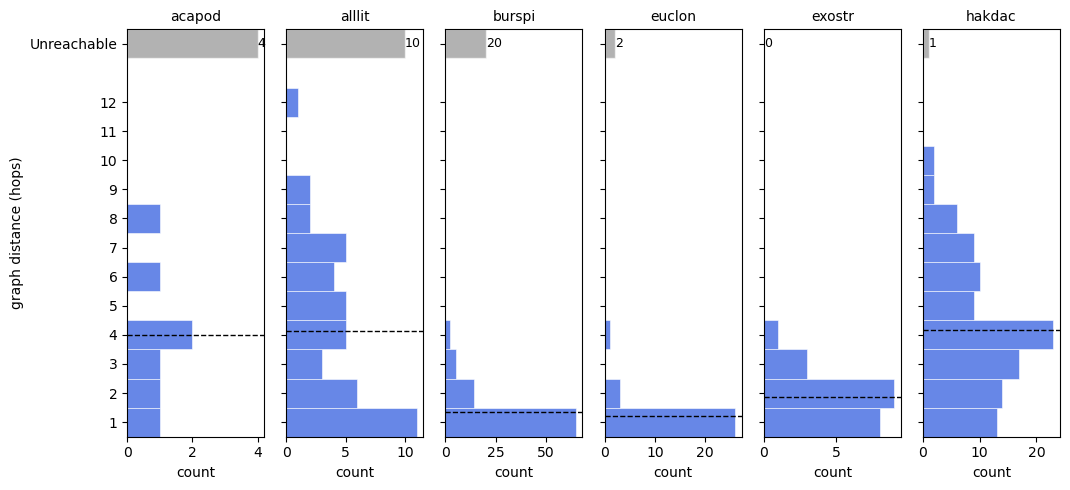

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# データ読み込み
df = pd.read_csv('plots_dfs/v_to_nearest_ray_distances_with_hops.csv')
df_h = df.copy()
df_h['is_unreach'] = ~np.isfinite(df_h['dist_hops'])

species_order = sorted(df_h['species'].dropna().unique())
n = len(species_order)

# 距離ビン定義
finite = df_h[np.isfinite(df_h['dist_hops'])]
hop_min = int(finite['dist_hops'].min()) if not finite.empty else 0
hop_max = int(finite['dist_hops'].max()) if not finite.empty else 0
bins = np.arange(hop_min - 0.5, hop_max + 1.5, 1)

# Unreachable を右端に置く
gap = 1.0
x_unreach = hop_max + gap + 1

fig, axes = plt.subplots(1, n, figsize=(1.8*n, 5), sharey=True)  # ← 縦型にするので 1行n列
if n == 1:
    axes = [axes]

for ax, sp in zip(axes, species_order):
    sub = df_h[df_h['species'] == sp]
    vals = sub.loc[np.isfinite(sub['dist_hops']), 'dist_hops'].astype(int).values

    if vals.size:
        counts, edges = np.histogram(vals, bins=bins)
        heights = np.diff(edges)
        bar_heights = heights * (1.0)  # 縦棒の幅（ヒスト幅）
        bottoms = edges[:-1]           # Y軸方向のビン位置

        # 縦型ヒスト（片側）
        ax.barh(bottoms, counts,
                height=bar_heights, align='edge',
                edgecolor='white', linewidth=0.5, alpha=0.8,
                color='royalblue')

        # 平均値に水平線
        mean = np.mean(vals)
        ax.axhline(mean, color='black', linestyle='--', linewidth=1)

    # Unreachable
    n_unreach = int(sub['is_unreach'].sum())
    ax.barh(x_unreach, n_unreach,
            height=1.0, align='center',
            color='grey', alpha=0.6, edgecolor='white')
    ax.text(n_unreach, x_unreach, f'{n_unreach}',
            ha='left', va='center', fontsize=9, color='black')

    # 種ラベル
    ax.set_title(sp, fontsize=10)
    ax.margins(y=0)

    # 目盛り設定
    yticks = np.arange(hop_min, hop_max + 1, 1)
    all_yticks = list(yticks) + [x_unreach]
    all_yticklabels = [str(x) for x in yticks] + ['Unreachable']
    ax.set_yticks(all_yticks)
    ax.set_yticklabels(all_yticklabels, rotation=0)

    ax.set_xlabel('count')

# Yラベル共通
axes[0].set_ylabel('graph distance (hops)')

plt.tight_layout()
plt.savefig('plots_dfs/hops_hist_vertical.png', dpi=300)
plt.savefig('plots_dfs/hops_hist_vertical.pdf')
plt.show()


In [5]:
summary_by_species = (
    df_h
    .groupby('species')
    .agg(
        mean_dist_hops=('dist_hops', lambda x: np.nanmean(x)),  # NaN除外
        unreachable_ratio=('is_unreach', 'mean'),               # True率
        count=('dist_hops', 'size')
    )
    .reset_index()
)

print(summary_by_species)


  species  mean_dist_hops  unreachable_ratio  count
0  acapod        4.000000           0.363636     11
1  alllit        4.136364           0.185185     54
2  burspi        1.348837           0.188679    106
3  euclon        1.200000           0.062500     32
4  exostr        1.857143           0.000000     21
5  hakdac        4.171429           0.009434    106


Saved -> plots_dfs/vv_shortest_paths_composition_LITE.csv


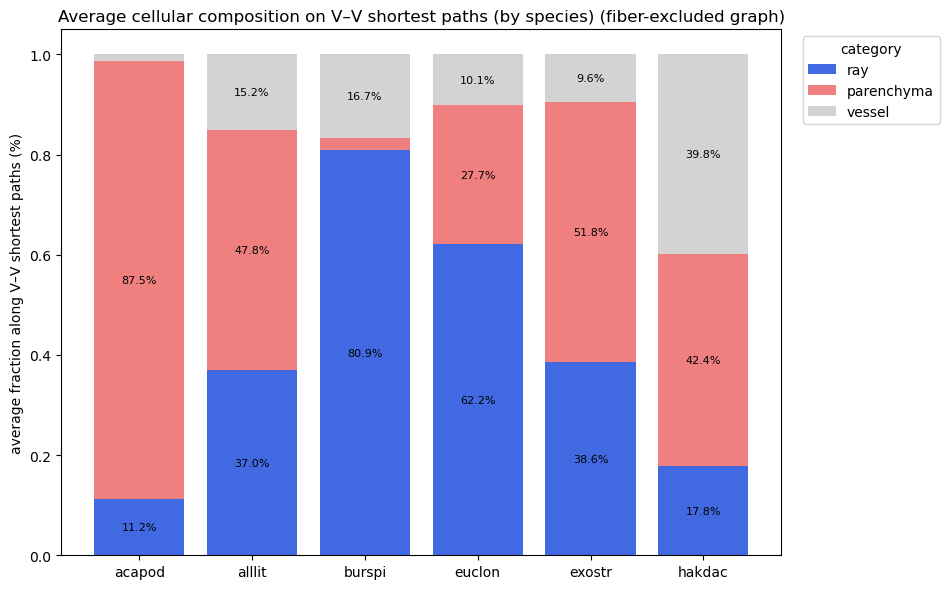

Saved -> plots_dfs/vv_avg_composition_by_species_LITE.png


In [6]:
# -*- coding: utf-8 -*-
import os, re, glob, pickle, random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

GRAPH_DIR = 'graphs_vpr_without_clearborder'
OUT_CSV = 'plots_dfs/vv_shortest_paths_composition_LITE.csv'
OUT_STACKED = 'plots_dfs/vv_avg_composition_by_species_LITE.png'
OUT_STACKEDpdf = 'plots_dfs/vv_avg_composition_by_species_LITE.pdf'

RANDOM_SEED = 42
MAX_SOURCES_PER_GRAPH = 20
TARGETS_PER_SOURCE    = 25
INCLUDE_ENDS = False

# （選択）fiber を組成出力からも外すなら fiber を消す
CATEGORIES = ['vessel', 'ray', 'parenchyma', 'unknown']  # ←必要なら fiber を削除
PLOT_ORDER = ['ray', 'parenchyma', 'vessel'] 
category_colors = {
    'parenchyma': 'lightcoral',
    'ray': 'royalblue', 
    'vessel': 'lightgray' # オレンジ

}


# unknown も経路に含めるか
ALLOW_UNKNOWN = False  # True にすると unknown も通行可

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

def species_from_fname(p):
    m = re.match(r'([A-Za-z]+)', os.path.basename(p))
    return m.group(1).lower() if m else os.path.basename(p)

def image_id_from_fname(p):
    return os.path.basename(p).replace('.gpickle','')

def simple_undirected(G):
    Gu = nx.Graph()
    Gu.add_nodes_from(G.nodes(data=True))
    Gu.add_edges_from(G.edges())
    return Gu

def rebuild_path_from_predecessor(pred, src, dst):
    path = [dst]
    cur = dst
    while cur != src:
        plist = pred.get(cur, [])
        if not plist:
            return None
        cur = plist[0]
        path.append(cur)
    path.reverse()
    return path

def path_categories(G, path, include_ends=True):
    if path is None:
        return []
    nodes = path if include_ends else path[1:-1]
    out = []
    for n in nodes:
        a = G.nodes[n].get('anatomy')
        out.append(a if a in CATEGORIES else 'unknown')
    return out

def compo_fraction(counts):
    tot = sum(counts.get(k,0) for k in CATEGORIES)
    if tot == 0:
        return {k: np.nan for k in CATEGORIES}
    return {k: counts.get(k,0)/tot for k in CATEGORIES}

records = []
files = sorted(glob.glob(os.path.join(GRAPH_DIR, '*.gpickle')))
if not files:
    print(f'No .gpickle in {GRAPH_DIR}')

for gp in files:
    try:
        with open(gp, 'rb') as f:
            G_raw = pickle.load(f)
    except Exception as e:
        print(f'[WARN] load failed: {gp}: {e}')
        continue

    # 無向単純化
    G = simple_undirected(G_raw)

    # -------- fiber を通さないサブグラフ H を構築 --------
    allowed = {'parenchyma', 'ray', 'vessel'}
    if ALLOW_UNKNOWN:
        allowed.add('unknown')
    keep_nodes = [n for n,d in G.nodes(data=True) if d.get('anatomy') in allowed]
    H = G.subgraph(keep_nodes).copy()
    # -----------------------------------------------------

    vessels = [n for n,d in H.nodes(data=True) if d.get('anatomy') == 'vessel']
    if len(vessels) < 2:
        continue

    species = species_from_fname(gp)
    image_id = image_id_from_fname(gp)

    for comp in nx.connected_components(H):
        vs = [v for v in vessels if v in comp]
        if len(vs) < 2:
            continue

        sources = random.sample(vs, min(len(vs), MAX_SOURCES_PER_GRAPH))

        for src in sources:
            # H 上で最短経路木（無重み）
            pred, _ = nx.predecessor(H, source=src, return_seen=True)

            reachable_vs = [v for v in vs if v != src and v in pred]
            if not reachable_vs:
                continue
            targets = random.sample(reachable_vs, min(len(reachable_vs), TARGETS_PER_SOURCE))

            for dst in targets:
                path = rebuild_path_from_predecessor(pred, src, dst)
                if not path:
                    continue
                cats = path_categories(H, path, include_ends=INCLUDE_ENDS)
                if not cats:
                    continue

                counts = {k:0 for k in CATEGORIES}
                for c in cats:
                    counts[c] = counts.get(c,0) + 1
                fracs = compo_fraction(counts)

                rec = {
                    'species': species,
                    'image_id': image_id,
                    'src': src,
                    'dst': dst,
                    'path_len': max(len(path)-1, 0),
                }
                for k in CATEGORIES:
                    rec[f'count_{k}'] = counts.get(k,0)
                    rec[f'frac_{k}']  = fracs.get(k, np.nan)
                records.append(rec)

df = pd.DataFrame(records)
if df.empty:
    print('No records. Try raising MAX_SOURCES_PER_GRAPH / TARGETS_PER_SOURCE.')
else:
    df.to_csv(OUT_CSV, index=False)
    print(f'Saved -> {OUT_CSV}')

    # 種ごとの平均組成（比率）
    df_mean = (
        df.groupby('species')[[f'frac_{k}' for k in CATEGORIES]]
          .mean()
          .rename(columns={f'frac_{k}': k for k in CATEGORIES})
    )
    
    # 積み上げ棒
    plt.figure(figsize=(max(8, 1.6*len(df_mean)), 6))
    ax = plt.gca()
    
    bottom = np.zeros(len(df_mean))
    x = np.arange(len(df_mean))
    
    containers = []  # ← 各層のBarContainerを保存
    for k in PLOT_ORDER:
        vals = df_mean[k].fillna(0).values
        bc = ax.bar(x, vals, bottom=bottom, label=k, color=category_colors.get(k, 'gray'))
        containers.append((bc, k))
        bottom += vals
    
    # パーセンテージのラベルを各セグメント中央に描く
    min_frac_label = 0.03  # 3%未満はラベル非表示（重なり防止用・任意）
    for bc, k in containers:
        vals = df_mean[k].fillna(0).values
        labels = [f'{v*100:.1f}%' if v >= min_frac_label else '' for v in vals]
        ax.bar_label(bc, labels=labels, label_type='center', fontsize=8, color='black')
    mpl.rcParams['pdf.fonttype'] = 42
    plt.xticks(x, df_mean.index, rotation=0)
    plt.ylabel('average fraction along V–V shortest paths (%)')
    ttl_note = ' (fiber-excluded graph)'
    plt.title('Average cellular composition on V–V shortest paths (by species)' + ttl_note)
    plt.legend(title='category', bbox_to_anchor=(1.02,1), loc='upper left')
    plt.tight_layout()
    plt.savefig(OUT_STACKED, dpi=300)
    plt.savefig(OUT_STACKEDpdf)
    plt.show()
    print(f'Saved -> {OUT_STACKED}')